# Partial Dependence Plots (PDPs) and Individual Conditional Expectation (ICE) Plots #

This Notebook follows the tutorial at: https://www.youtube.com/watch?v=1NJxol4rGgA&t=1s
<br><br>
Both Partial Dependence Plots (PDPs) and Individual Conditional Expectation  (ICE) plots are a popular explainable AI (XAI) method. They can visualise the relationships used by a machine learning model to make predictions. In this video, we will see how to apply the methods using Python. We will use the scikit-learn package and the PartialDependenceDisplay & partial_dependence functions. 
<br><br>
Dataset: https://www.kaggle.com/datasets/conorsully1/pdp-and-ice-plots/settings


In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
%matplotlib inline

from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

from sklearn.inspection import PartialDependenceDisplay
from sklearn.inspection import partial_dependence

from sklearn.metrics import accuracy_score, confusion_matrix


In [5]:
# Load Dataset
data = pd.read_csv('./data/PDP_ICE.csv', sep='\t')

# Get Features and Target
y = data['price']
X = data.drop(['price'], axis=1)

print(len(data))
data.head()



1000


,owner_age,car_age,km_driven,repairs,car_type,price
0,23,2.17,25142.768002,24,0,4077
1,26,18.92,120164.547502,17,0,2804
2,35,24.90,90244.499657,13,0,4432
3,34,1.93,15384.326615,18,0,5340
4,67,6.88,32319.146178,19,0,4053


## Sklearn Model

In [6]:
# Model
rf = RandomForestRegressor(max_depth=4, n_estimators=100, random_state=0)
rf.fit(X, y)

# Get Predictions
y_pred = rf.predict(X)


Text(0.5, 0, 'Actual Price')

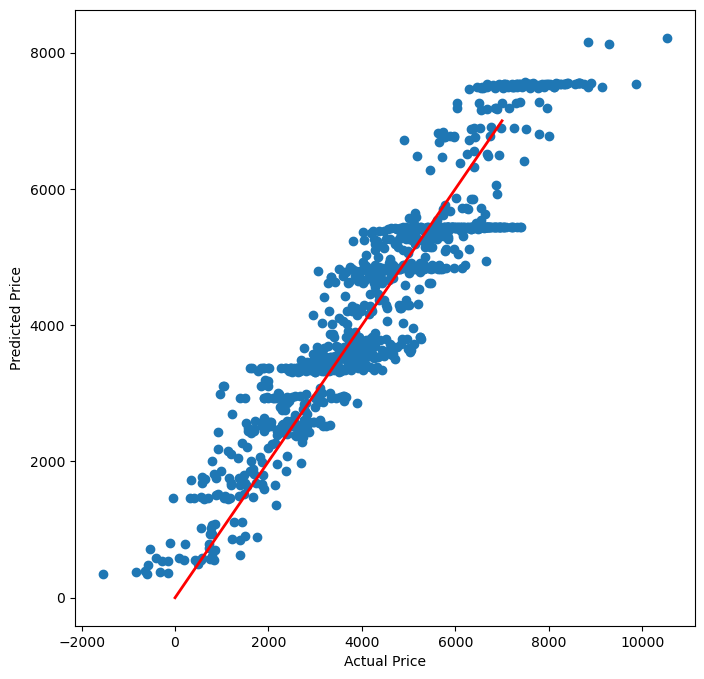

In [7]:
# Model Evaluation
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8,8))

plt.scatter(y, y_pred)
plt.plot([0,7000], [0,7000], color='r', linestyle='-', linewidth=2)

plt.ylabel('Predicted Price')
plt.xlabel('Actual Price')


## Explaining PDPs

In [9]:
# Get 1000 individual prediction lines
pdp_lines = partial_dependence(rf, X, ["car_age"],percentiles=(0,1), grid_resolution=100, kind = 'individual')

len(pdp_lines['individual'][0])

1000

In [12]:
print(np.shape(pdp_lines['grid_values']))
print(np.shape(pdp_lines['individual']))

(1, 100)
(1, 1000, 100)


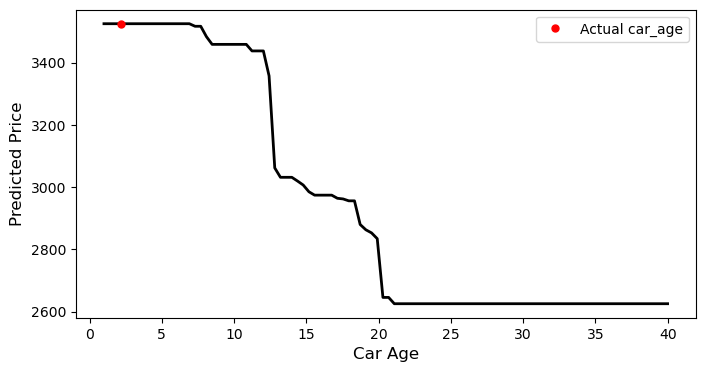

In [13]:
# Plot the first prediction line
plt.figure(figsize=(8,4))

plt.plot(pdp_lines['grid_values'][0], pdp_lines['individual'][0][0], color='black', linestyle='-', linewidth=2)

# Add red dot for actual car age
car_0 = data.iloc[0]
plt.plot(car_0['car_age'], y_pred[0], 'ro', markersize =5, label='Actual car_age')

plt.ylabel('Predicted Price', size =12)
plt.xlabel('Car Age', size =12)
plt.legend(loc='upper right')

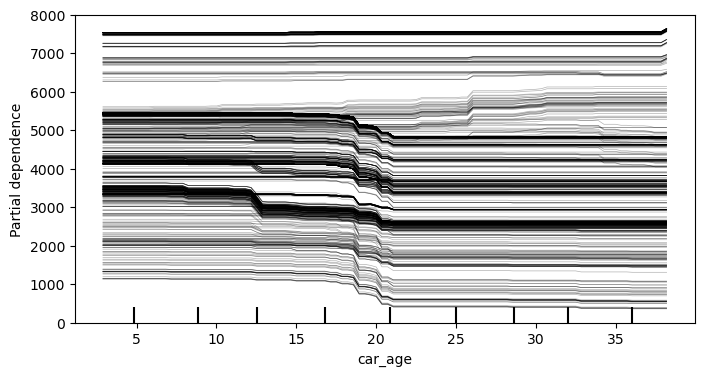

In [14]:
# ICE Plot
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8,4))
PartialDependenceDisplay.from_estimator(rf, X, ["car_age"], kind='individual', ice_lines_kw={"color":"black"}, ax=ax)

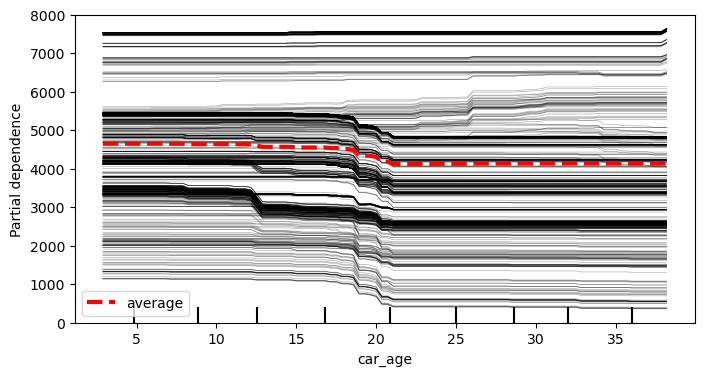

In [16]:
# ICE Plot
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8,4))
PartialDependenceDisplay.from_estimator(rf, X, ["car_age"], kind='both', ice_lines_kw={"color":"black"}, pd_line_kw={"color":"red", "lw":3, 'linestyle':'--'}, ax=ax)

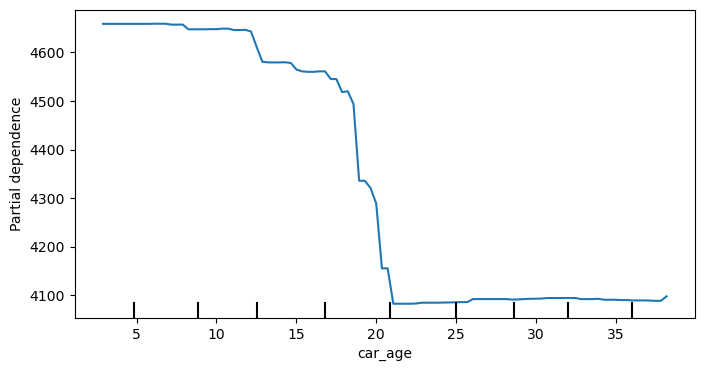

In [19]:
# PDP for car_age
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8,4))
PartialDependenceDisplay.from_estimator(rf, X, ["car_age"], kind='average', ax=ax)

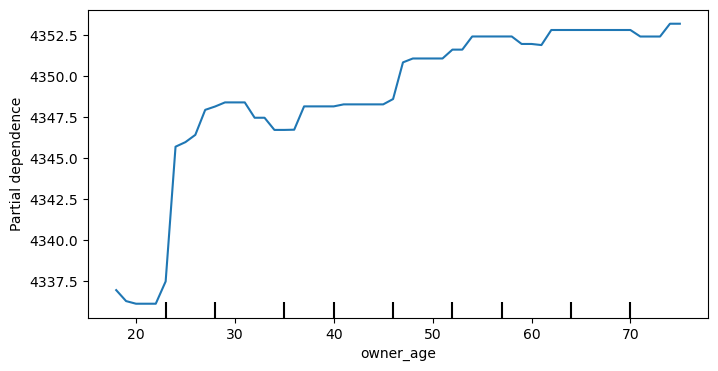

In [20]:
# PDP for owner_age
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8,4))
PartialDependenceDisplay.from_estimator(rf, X, ["owner_age"], kind='average', ax=ax)

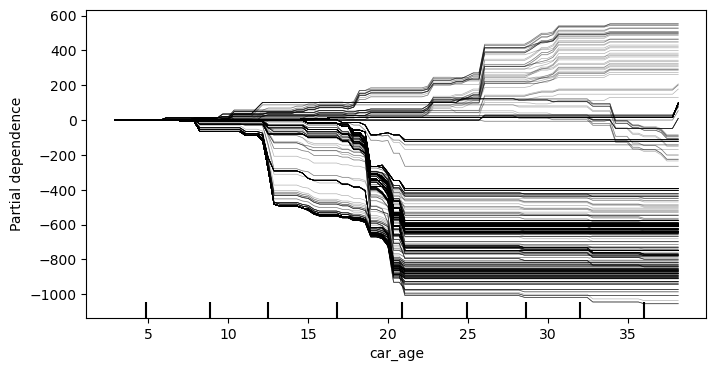

In [21]:
# ICE Plot
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8,4))
PartialDependenceDisplay.from_estimator(rf, X, ["car_age"], kind='individual', ice_lines_kw={"color":"black"}, ax=ax, centered=True)

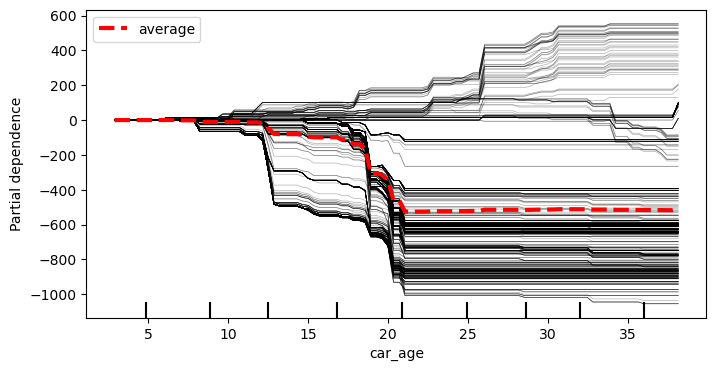

In [22]:
# ICE Plot
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8,4))
PartialDependenceDisplay.from_estimator(rf, X, ["car_age"], kind='both', ice_lines_kw={"color":"black"}, pd_line_kw={"color":"red", "lw":3, 'linestyle':'--'}, ax=ax, centered=True)

## Custom ICE Plot

In [23]:
# Start by getting all the data needed to create the ICE Plot
# Get 1000 individual prediction lines
pdp_lines = partial_dependence(rf, X, ["car_age"],percentiles=(0,1), grid_resolution=100, kind = 'both')

# Center the lines
for i in range(0,1000):
    pdp_start = pdp_lines['individual'][0][i][0]
    pdp_lines['individual'][0][i] = pdp_lines['individual'][0][i] - pdp_start
    

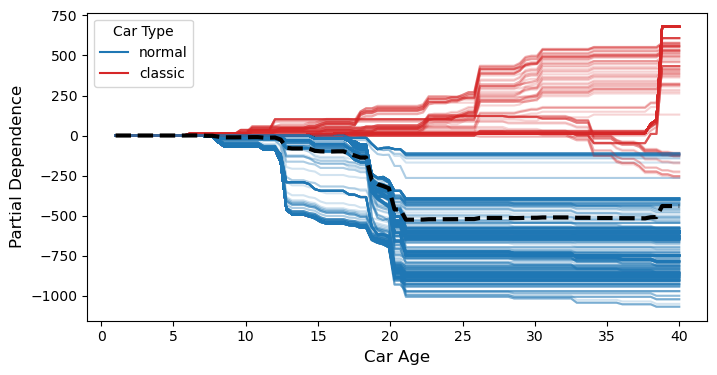

In [26]:
# Plot an ice plot colored by car type
color_feature = 'car_type'
colors = ['tab:blue', 'tab:red']
plt.figure(figsize=(8,4))

# ICE Plot
for i in range(0,1000):
    color = colors[X[color_feature].values[i]]
    plt.plot(pdp_lines['grid_values'][0], pdp_lines['individual'][0][i],color=color, alpha=0.2)

# PDP Line
pdp = pdp_lines['average'][0] - pdp_lines['average'][0][0]
plt.plot(pdp_lines['grid_values'][0], pdp, color='black', linestyle='--', linewidth=3)

plt.ylabel('Partial Dependence', size =12)
plt.xlabel('Car Age', size =12)

# Add custom legend with color for each car type
plt.legend(handles=[plt.Line2D([0], [0], color='tab:blue', label='normal'),
                    plt.Line2D([0], [0], color='tab:red', label='classic')], 
                    title="Car Type", loc='upper left')

## 2D PDP

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


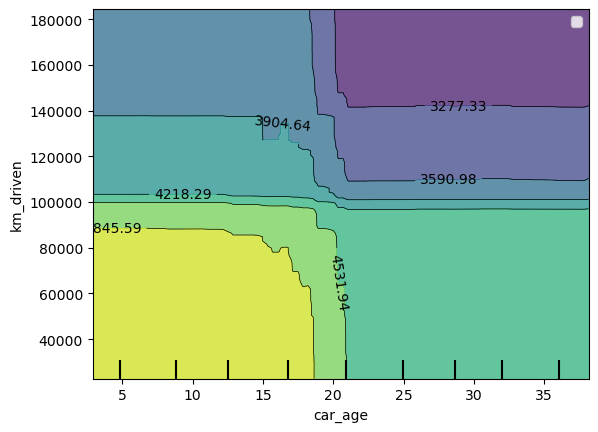

In [ ]:
#  2D PDP
features = [("car_age", "km_driven")]
PartialDependenceDisplay.from_estimator(rf, X, features)

## PDP for Categorical Features

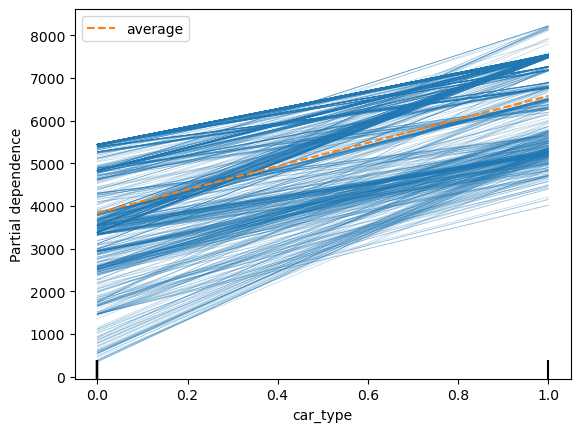

In [29]:
features = ['car_type']
PartialDependenceDisplay.from_estimator(rf, X, features, kind = 'both')

This shouldn't be displayed as lines due to the discrete nature of categorical features.  We will make a custom plot instead.

Text(0.5, 0, 'Car Type')

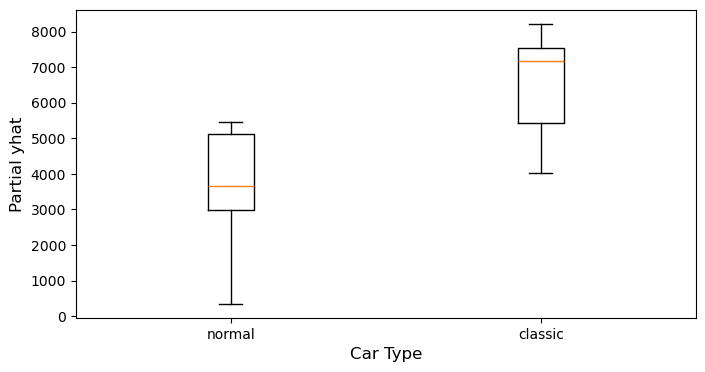

In [30]:
# PDP boxplot for car type
features = ['car_type']
pdp_lines = partial_dependence(rf, X, features, kind = 'both')

# Get ICE Values
ice = pdp_lines['individual'][0]
normal_ice = [i[0] for i in ice]
classic_ice = [i[1] for i in ice]   
data = [normal_ice, classic_ice]

# Plot ice values
plt.figure(figsize=(8,4))
labels = ['normal', 'classic']
plt.boxplot(data, labels=labels)
plt.ylabel('Partial yhat', size =12)
plt.xlabel('Car Type', size =12)

## ICE Plots for Binary Target Variables

In [31]:
# Binary Target Variable
avg_y = np.mean(y)
y_binary = [1 if y_>avg_y else 0 for y_ in y]

# Train Model
rfc = RandomForestClassifier(max_depth=4, n_estimators=100, random_state=0)
rfc.fit(X, y_binary)

# Get Predictions
y_pred = rfc.predict(X)

print(confusion_matrix(y_binary, y_pred))
print(accuracy_score(y_binary, y_pred))

[[462  49]
 [ 27 462]]
0.924


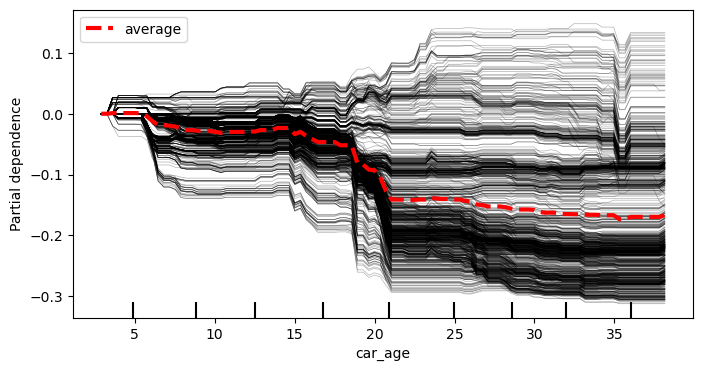

In [32]:
# ICE Plot
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8,4))
PartialDependenceDisplay.from_estimator(rfc, X, ["car_age"], kind='both', ice_lines_kw={"color":"black"}, pd_line_kw={"color":"red", "lw":3, 'linestyle':'--'}, ax=ax, centered=True)